# Aim: Demonstrate the curse of dimensionality by comparing KNN performance with different numbers of features.

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [39]:
df = pd.read_csv("diabetes.csv")
df.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,50,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
2,183,64,0,0,23.3,0.672,52,1
3,150,66,23,94,28.1,0.167,21,0
4,150,40,35,168,43.1,2.288,33,1


In [40]:
x = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [41]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=42
)

In [42]:
feature_values = [2, 3, 4, 5, 6, 7]
accuracy_list = []

for n in feature_values:
    x_train_new = x_train.iloc[:, :n]
    x_test_new = x_test.iloc[:, :n]

    scaler = StandardScaler()
    x_train_new = scaler.fit_transform(x_train_new)
    x_test_new = scaler.transform(x_test_new)

    knn_clf = KNeighborsClassifier(n_neighbors=5)
    knn_clf.fit(x_train_new, y_train)
    y_pred = knn_clf.predict(x_test_new)

    accuracy = accuracy_score(y_test, y_pred)
    accuracy_list.append(accuracy)
    print(f"Number of Features = {n} ---> Accuracy = {accuracy}")

Number of Features = 2 ---> Accuracy = 0.71875
Number of Features = 3 ---> Accuracy = 0.65625
Number of Features = 4 ---> Accuracy = 0.7135416666666666
Number of Features = 5 ---> Accuracy = 0.734375
Number of Features = 6 ---> Accuracy = 0.6927083333333334
Number of Features = 7 ---> Accuracy = 0.6822916666666666


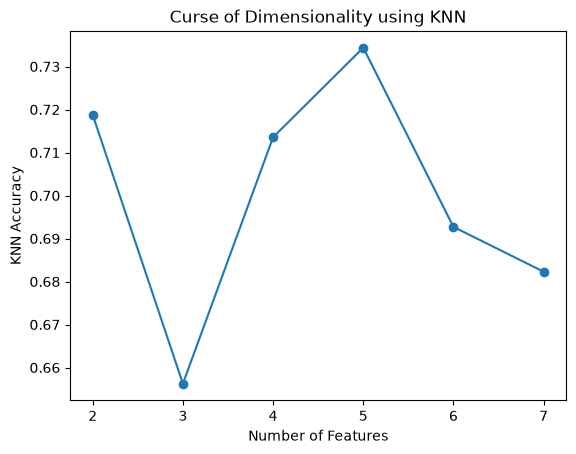

In [43]:
plt.plot(feature_values, accuracy_list, marker='o')
plt.xlabel('Number of Features')
plt.ylabel('KNN Accuracy')
plt.title('Curse of Dimensionality using KNN')
plt.show()